In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")


In [2]:
dataset=pd.read_csv("Telco_Customer_Churn_Dataset.csv")
dataset.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
dataset.shape

(7043, 21)

In [4]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
dataset.drop(columns=["customerID"],inplace=True)

In [6]:
dataset.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
dataset.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [8]:
for col in dataset.columns:
    if not col in ["tenure","MonthlyCharges","TotalCharges"]:
        print(col,dataset[col].unique())
        print("----------------------")

gender ['Female' 'Male']
----------------------
SeniorCitizen [0 1]
----------------------
Partner ['Yes' 'No']
----------------------
Dependents ['No' 'Yes']
----------------------
PhoneService ['No' 'Yes']
----------------------
MultipleLines ['No phone service' 'No' 'Yes']
----------------------
InternetService ['DSL' 'Fiber optic' 'No']
----------------------
OnlineSecurity ['No' 'Yes' 'No internet service']
----------------------
OnlineBackup ['Yes' 'No' 'No internet service']
----------------------
DeviceProtection ['No' 'Yes' 'No internet service']
----------------------
TechSupport ['No' 'Yes' 'No internet service']
----------------------
StreamingTV ['No' 'Yes' 'No internet service']
----------------------
StreamingMovies ['No' 'Yes' 'No internet service']
----------------------
Contract ['Month-to-month' 'One year' 'Two year']
----------------------
PaperlessBilling ['Yes' 'No']
----------------------
PaymentMethod ['Electronic check' 'Mailed check' 'Bank transfer (automatic)

In [9]:
for col in ["tenure","MonthlyCharges","TotalCharges"]:
    print(col,len(dataset[dataset[col]==" "]))
    print("----------")

tenure 0
----------
MonthlyCharges 0
----------
TotalCharges 11
----------


In [10]:
dataset["TotalCharges"]=dataset["TotalCharges"].replace({" ":"0.0"}).astype(float)

In [11]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [12]:
dataset["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

EXPLANATORY DATA ANALYSIS

In [13]:
dataset.shape

(7043, 20)

In [14]:
dataset.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [15]:
dataset.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [16]:
def plot_distribution(dataset,column_name):
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    sns.histplot(dataset[column_name],kde=True)
    plt.title(f"Distribution of {column_name}")

    col_mean=dataset[column_name].mean()
    col_median=dataset[column_name].median()
    plt.axvline(col_mean,color="red",linestyle="--",label="Mean")
    plt.axvline(col_median,color="blue",linestyle="--",label="Median")

    plt.legend()
    plt.subplot(1,2,2)
    sns.boxplot(y=dataset[column_name])
    plt.title(f"Boxplot of {column_name}")
    plt.show()

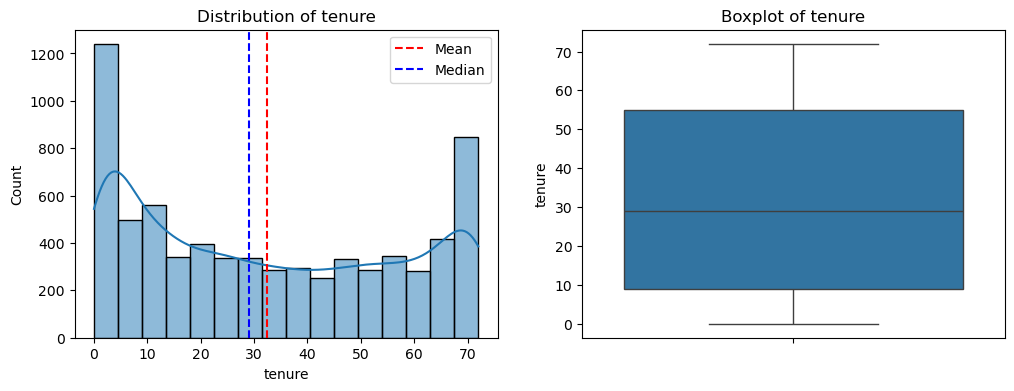

In [17]:
plot_distribution(dataset,"tenure")

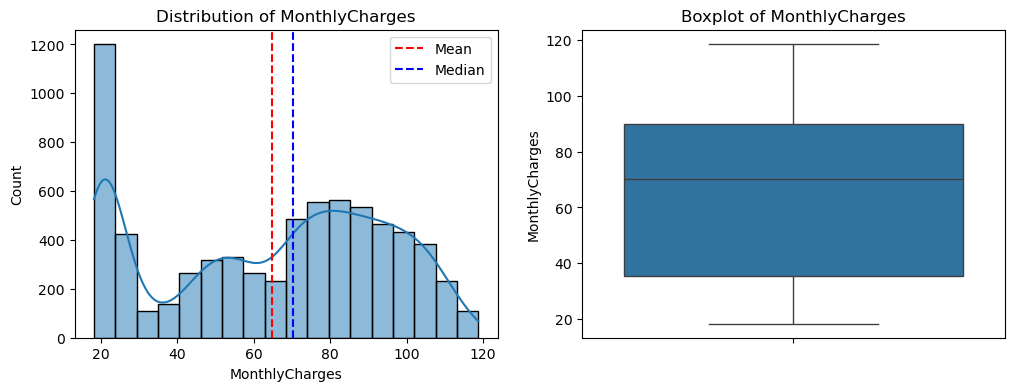

In [18]:
plot_distribution(dataset,"MonthlyCharges")

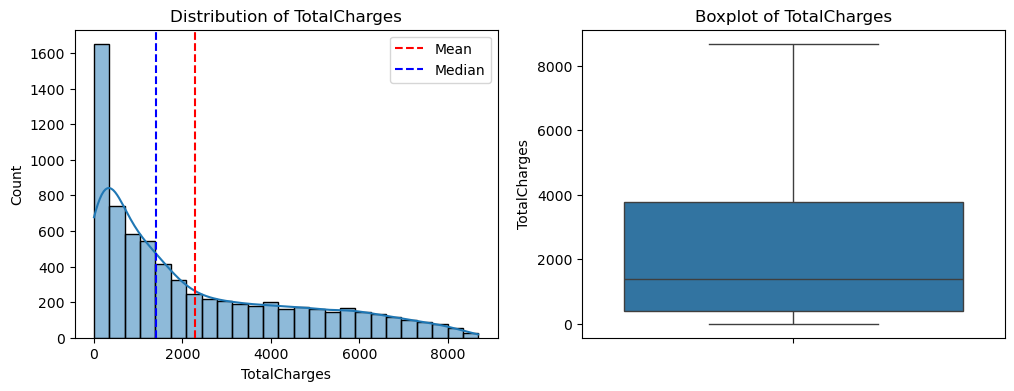

In [19]:
plot_distribution(dataset,"TotalCharges")

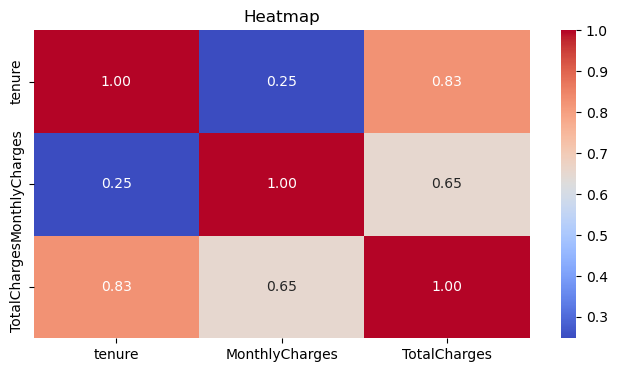

In [20]:
plt.figure(figsize=(8,4))
sns.heatmap(dataset[["tenure","MonthlyCharges","TotalCharges"]].corr(),annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Heatmap")
plt.show()

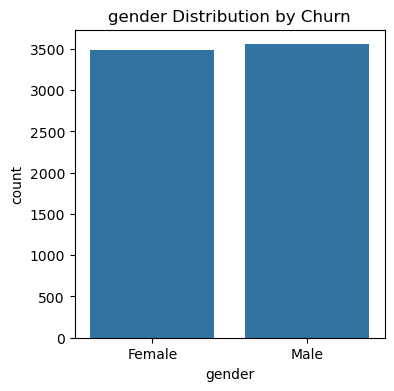

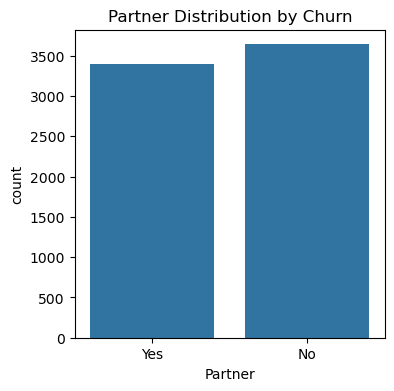

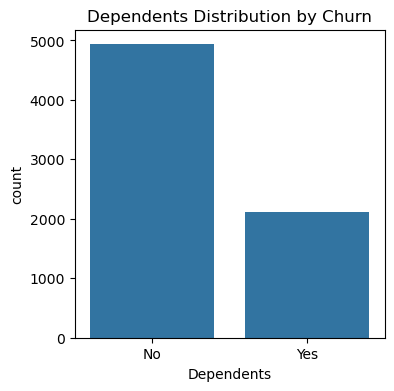

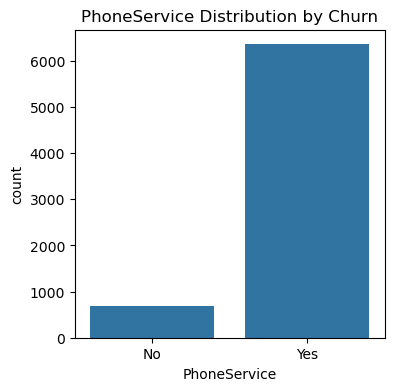

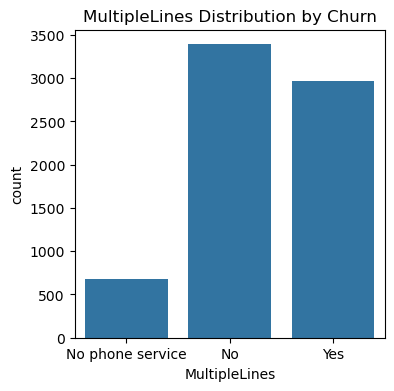

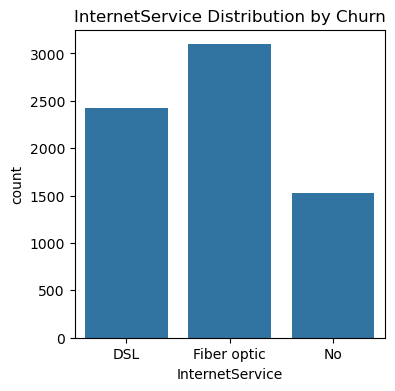

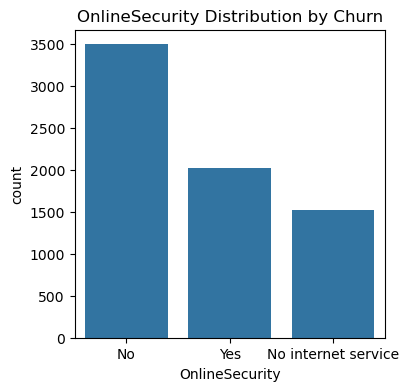

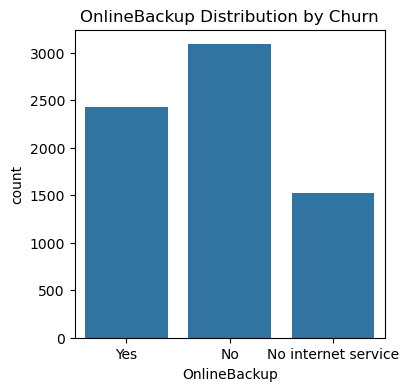

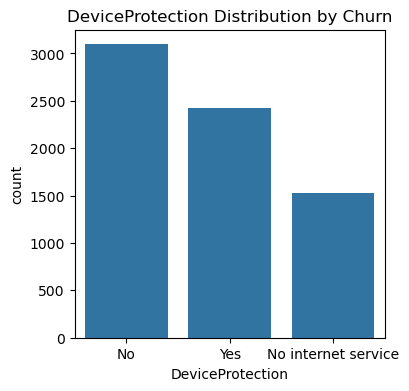

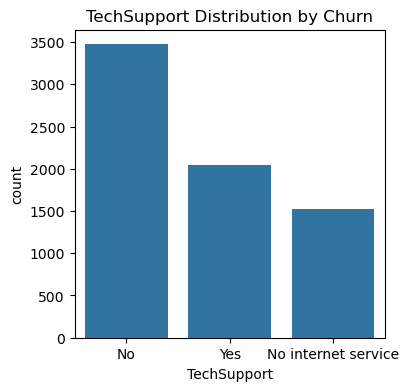

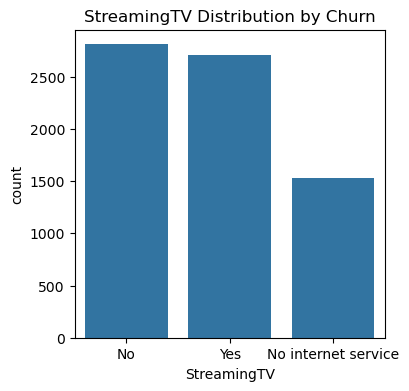

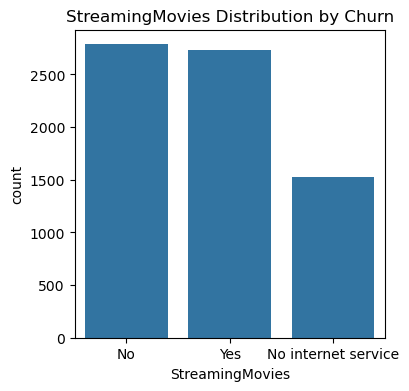

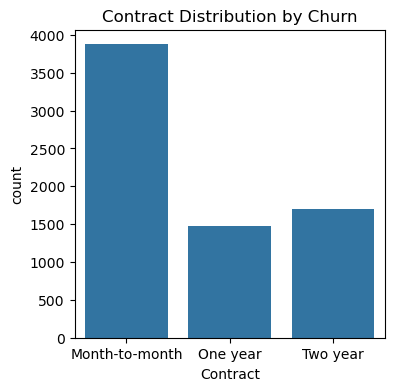

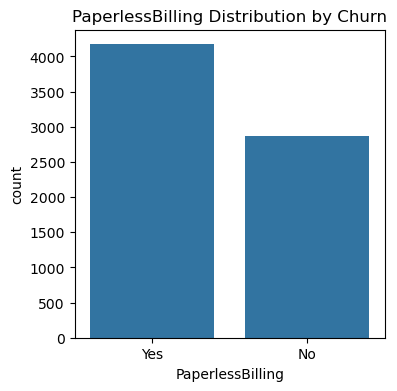

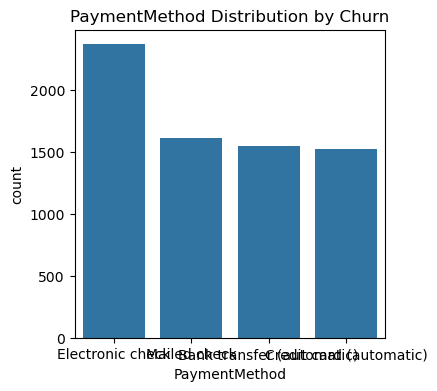

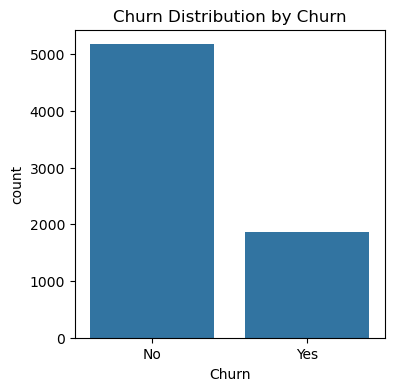

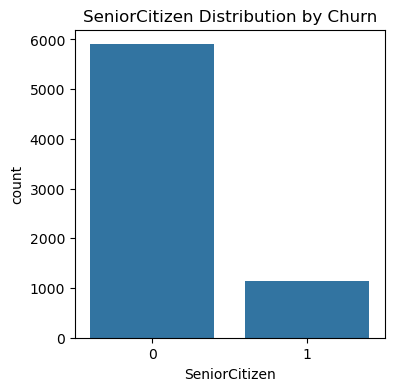

In [21]:
categorical_cols=dataset.select_dtypes(include="object").columns.to_list() + ["SeniorCitizen"]

for col in categorical_cols:
    plt.figure(figsize=(4,4))
    # sns.countplot(data=dataset,x=col,hue="Churn")
    sns.countplot(x=dataset[col])
    plt.title(f"{col} Distribution by Churn")
    plt.show()

In [22]:
# label encoding 
dataset["Churn"]=dataset["Churn"].replace({"Yes": 1,"No": 0})

In [23]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [24]:
objects_columns=dataset.select_dtypes(include="object").columns

In [25]:
objects_columns

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')

In [26]:
from sklearn.preprocessing import LabelEncoder
encoders={}

for column in objects_columns:
    label_encoder=LabelEncoder()
    dataset[column]=label_encoder.fit_transform(dataset[column])
    encoders[column]=label_encoder

In [27]:
encoders

{'gender': LabelEncoder(),
 'Partner': LabelEncoder(),
 'Dependents': LabelEncoder(),
 'PhoneService': LabelEncoder(),
 'MultipleLines': LabelEncoder(),
 'InternetService': LabelEncoder(),
 'OnlineSecurity': LabelEncoder(),
 'OnlineBackup': LabelEncoder(),
 'DeviceProtection': LabelEncoder(),
 'TechSupport': LabelEncoder(),
 'StreamingTV': LabelEncoder(),
 'StreamingMovies': LabelEncoder(),
 'Contract': LabelEncoder(),
 'PaperlessBilling': LabelEncoder(),
 'PaymentMethod': LabelEncoder()}

In [28]:
import pickle
with open("encoder.pkl","wb") as f:
    pickle.dump(encoders,f)

In [29]:
from sklearn.preprocessing import StandardScaler

In [30]:
numerical_col=["tenure","MonthlyCharges","TotalCharges"]
scaler=StandardScaler()
dataset[numerical_col]=scaler.fit_transform(dataset[numerical_col])

In [31]:
dataset["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [32]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,roc_auc_score

In [33]:
X=dataset.drop(columns=["Churn"])
y=dataset["Churn"]

In [34]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [35]:
y_train.value_counts()

Churn
0    4138
1    1496
Name: count, dtype: int64

In [36]:
smote=SMOTE(random_state=42)

In [37]:
X_train_smote,y_train_smote=smote.fit_resample(X_train,y_train)

In [38]:
y_train_smote.value_counts()

Churn
0    4138
1    4138
Name: count, dtype: int64

In [39]:
models = {
    "Random Forest":RandomForestClassifier(random_state=42),
    "XGBoost":XGBClassifier(random_state=42)
}

In [40]:
hyperparameters={
    "Random Forest" :{
        "n_estimators":[50,100,200],
        "max_depth":[5,10,None],
    },
    "XGBoost" : {
        "learning_rate":[0.01,0.1,0.2],
        "max_depth":[3,5,7],
    }
}
    

In [41]:
best_models={}
for model_name,model in models.items():
    print(f"Tunning {model_name}......")
    grid=GridSearchCV(estimator=model,param_grid=hyperparameters[model_name],cv=5,scoring="accuracy")
    grid.fit(X_train_smote,y_train_smote)
    best_models[model_name]=grid.best_estimator_
    print(f"Best parameters for{model_name} : {grid.best_params_}")
    print(f"Best Accuracy for {model_name} : {grid.best_score_: .2f}\n")

Tunning Random Forest......
Best parameters forRandom Forest : {'max_depth': None, 'n_estimators': 200}
Best Accuracy for Random Forest :  0.84

Tunning XGBoost......
Best parameters forXGBoost : {'learning_rate': 0.2, 'max_depth': 7}
Best Accuracy for XGBoost :  0.82



In [42]:
best_models

{'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
 'XGBoost': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=None, device=None, early_stopping_rounds=None,
               enable_categorical=False, eval_metric=None, feature_types=None,
               feature_weights=None, gamma=None, grow_policy=None,
               importance_type=None, interaction_constraints=None,
               learning_rate=0.2, max_bin=None, max_cat_threshold=None,
               max_cat_to_onehot=None, max_delta_step=None, max_depth=7,
               max_leaves=None, min_child_weight=None, missing=nan,
               monotone_constraints=None, multi_strategy=None, n_estimators=None,
               n_jobs=None, num_parallel_tree=None, ...)}

In [43]:
with open("best_model.pkl","wb") as f:
    pickle.dump(best_models["Random Forest"],f)

In [44]:
with open("scaler.pkl","wb") as f:
    pickle.dump(scaler,f)

In [45]:
y_test_pred=best_models["Random Forest"].predict(X_test)
y_test_prob=best_models["Random Forest"].predict_proba(X_test)

In [47]:
y_test_pred

array([1, 0, 0, ..., 0, 0, 0], shape=(1409,))

In [48]:
y_test_prob

array([[0.095, 0.905],
       [0.6  , 0.4  ],
       [0.99 , 0.01 ],
       ...,
       [0.985, 0.015],
       [0.965, 0.035],
       [0.615, 0.385]], shape=(1409, 2))

In [49]:
print(f"Accuracy score:",accuracy_score(y_test,y_test_pred))
print(f"ROC-AUC score:",roc_auc_score(y_test,y_test_pred))
print(f"confusion matrix:\n",confusion_matrix(y_test,y_test_pred))
print(f"Classsification Report:\n",classification_report(y_test,y_test_pred))

Accuracy score: 0.7806955287437899
ROC-AUC score: 0.7444944465721945
confusion matrix:
 [[851 185]
 [124 249]]
Classsification Report:
               precision    recall  f1-score   support

           0       0.87      0.82      0.85      1036
           1       0.57      0.67      0.62       373

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.79      1409



In [50]:
with open("best_model.pkl","rb") as f:
    loaded_model=pickle.load(f)
with open("encoder.pkl","rb") as f:
    encoders=pickle.load(f)
with open("scaler.pkl","rb") as f:
    scaler_data=pickle.load(f)

In [51]:
def make_prediction(input_data):
    input_df=pd.DataFrame([input_data])
    for col,encoder in encoders.items():
        input_df[col]=encoder.transform(input_df[col])
    numerical_cols=["tenure","MonthlyCharges","TotalCharges"]
    input_df[numerical_cols]=scaler_data.transform(input_df[numerical_cols])
    prediction=loaded_model.predict(input_df)[0]
    probability=loaded_model.predict_proba(input_df)[0,1]
    return "Churn" if prediction ==1 else "No Churn" ,probability
    

In [52]:
dataset.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [57]:
example_input={
    "gender" : "Female",
    "SeniorCitizen":0,
    "Partner" :"Yes",
    "Dependents" :"No",
    "tenure" : 1,
    "PhoneService" :"No",
    "MultipleLines" :"No phone service",
    "InternetService" :"DSL",
    "OnlineSecurity" :"No",
    "OnlineBackup" :"Yes",
    "DeviceProtection" :"No",
    "TechSupport":"No",
    "StreamingTV" :"No",
    "StreamingMovies" :"No",
    "Contract" :"Month-to-month",
    "PaperlessBilling" :"Yes",
    "PaymentMethod" :"Electronic check",
    "MonthlyCharges" :29.85,
    "TotalCharges" :29.85
}

In [58]:
prediction,prob=make_prediction(example_input)

In [61]:
 print(f"Prediction: {prediction}, Probability:{prob: .2f}")

Prediction: No Churn, Probability: 0.26
